In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

In [15]:
a = 	[ 1.39,	1.28,	1.27,	1.26,	1.25,	1.24,	1.22,	1.21,	1.19,	1.18 ]
b = 	[ 1.27,	1.53,	1.55,	1.58,	1.62,	1.66,	1.71,	1.76,	1.82,	1.89 ]
c = 	[ 0.39,	0.30,	0.31,	0.32,	0.33,	0.34,	0.34,	0.35,	0.35,	0.36 ]
s = 	[ 0.50,	0.60,	0.70,	0.80,	0.90,	1.00,	1.10,	1.20,	1.30,	1.40 ]

a = np.array(a)
b = np.array(b)
c = np.array(c)
s = np.array(s)

In [16]:
x = np.linspace(0, 1, 11)
X = np.zeros((len(a), len(x)+1))
for ii in range(len(a)):
    X[ii,0:len(x)] = x # vai até o penúltimo (que dor de cabeça!)
    X[ii,len(x)] = s[ii]
print(X.shape)
X

(10, 12)


array([[0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 0.5],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 0.6],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 0.7],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 0.8],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 0.9],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1. ],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.2],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.3],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.4]])

In [17]:
Y = np.ones((len(a), len(x)))
for ii in range(len(a)):
    Y[ii,:] = a[ii] * np.exp(-b[ii]*X[ii,0:len(x)]) - c[ii]
Y = np.round(Y, 2)
print(Y.shape)
Y

(10, 11)


array([[ 1.  ,  0.83,  0.69,  0.56,  0.45,  0.35,  0.26,  0.18,  0.11,
         0.05,  0.  ],
       [ 0.98,  0.8 ,  0.64,  0.51,  0.39,  0.3 ,  0.21,  0.14,  0.08,
         0.02, -0.02],
       [ 0.96,  0.78,  0.62,  0.49,  0.37,  0.28,  0.19,  0.12,  0.06,
         0.  , -0.04],
       [ 0.94,  0.76,  0.6 ,  0.46,  0.35,  0.25,  0.17,  0.1 ,  0.04,
        -0.02, -0.06],
       [ 0.92,  0.73,  0.57,  0.44,  0.32,  0.23,  0.14,  0.07,  0.01,
        -0.04, -0.08],
       [ 0.9 ,  0.71,  0.55,  0.41,  0.3 ,  0.2 ,  0.12,  0.05, -0.01,
        -0.06, -0.1 ],
       [ 0.88,  0.69,  0.53,  0.39,  0.28,  0.18,  0.1 ,  0.03, -0.03,
        -0.08, -0.12],
       [ 0.86,  0.66,  0.5 ,  0.36,  0.25,  0.15,  0.07,  0.  , -0.05,
        -0.1 , -0.14],
       [ 0.84,  0.64,  0.48,  0.34,  0.22,  0.13,  0.05, -0.02, -0.07,
        -0.12, -0.16],
       [ 0.82,  0.62,  0.45,  0.31,  0.19,  0.1 ,  0.02, -0.05, -0.1 ,
        -0.14, -0.18]])

In [18]:
# Set random seed
tf.random.set_seed(42)

# Create a model using the Sequential API
model = tf.keras.Sequential([
#   tf.keras.layers.Flatten(),
  tf.keras.layers.Dense(111, activation='relu'),
  tf.keras.layers.Dense(111, activation='relu'),
  tf.keras.layers.Dense(111, activation='relu'),
  tf.keras.layers.Dense(111, activation='relu'),
  tf.keras.layers.Dense(111, activation='relu'),
  tf.keras.layers.Dense(Y.shape[1], activation='linear')
])

In [19]:
# Compile the model
model.compile(loss=tf.keras.losses.mse,
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), 
              metrics=["mse","mae"])

In [20]:
# Fit the model
# model.fit(X, y, epochs=5) # this will break with TensorFlow 2.7.0+
# history = model.fit(tf.expand_dims(X, axis=-1), saida, epochs=500, verbose=0)
history = model.fit(X, Y, epochs=1000, verbose=0)
print("treinada...")

treinada...


In [21]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_6 (Dense)             (None, 111)               1443      
                                                                 
 dense_7 (Dense)             (None, 111)               12432     
                                                                 
 dense_8 (Dense)             (None, 111)               12432     
                                                                 
 dense_9 (Dense)             (None, 111)               12432     
                                                                 
 dense_10 (Dense)            (None, 111)               12432     
                                                                 
 dense_11 (Dense)            (None, 11)                1232      
                                                                 
Total params: 52,403
Trainable params: 52,403
Non-trai

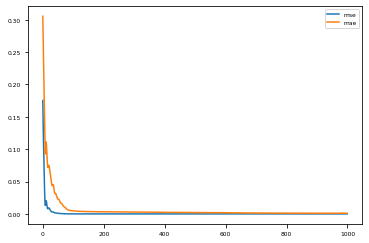

In [22]:
plt.plot(history.history["mse"], label="mse")
plt.plot(history.history["mae"], label="mae")
plt.legend()
plt.show()

In [23]:
x_pred = x
X_pred = np.zeros((len(a), len(x)+1))
for ii in range(len(a)):
    X_pred[ii,0:len(x)] = x_pred
    X_pred[ii,len(x)] = s[ii]
print(X_pred.shape)
# X_pred = X[0:1]
X_pred

(10, 12)


array([[0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 0.5],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 0.6],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 0.7],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 0.8],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 0.9],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1. ],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.2],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.3],
       [0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.4]])

In [24]:
Y_pred = model.predict(X_pred)
Y_pred.shape, X_pred.shape
Y_pred[0]

1/1 [==============================] - 0s 53ms/step


array([ 9.9971193e-01,  8.2937348e-01,  6.8969649e-01,  5.5978525e-01,
        4.4930661e-01,  3.4930989e-01,  2.5969833e-01,  1.7962849e-01,
        1.0983113e-01,  4.9593836e-02, -1.4351960e-04], dtype=float32)

In [25]:
X_pred_del = np.delete(X_pred, X_pred.shape[1]-1, axis=1)
X_pred_del[0]
Y_pred[0]

array([ 9.9971193e-01,  8.2937348e-01,  6.8969649e-01,  5.5978525e-01,
        4.4930661e-01,  3.4930989e-01,  2.5969833e-01,  1.7962849e-01,
        1.0983113e-01,  4.9593836e-02, -1.4351960e-04], dtype=float32)

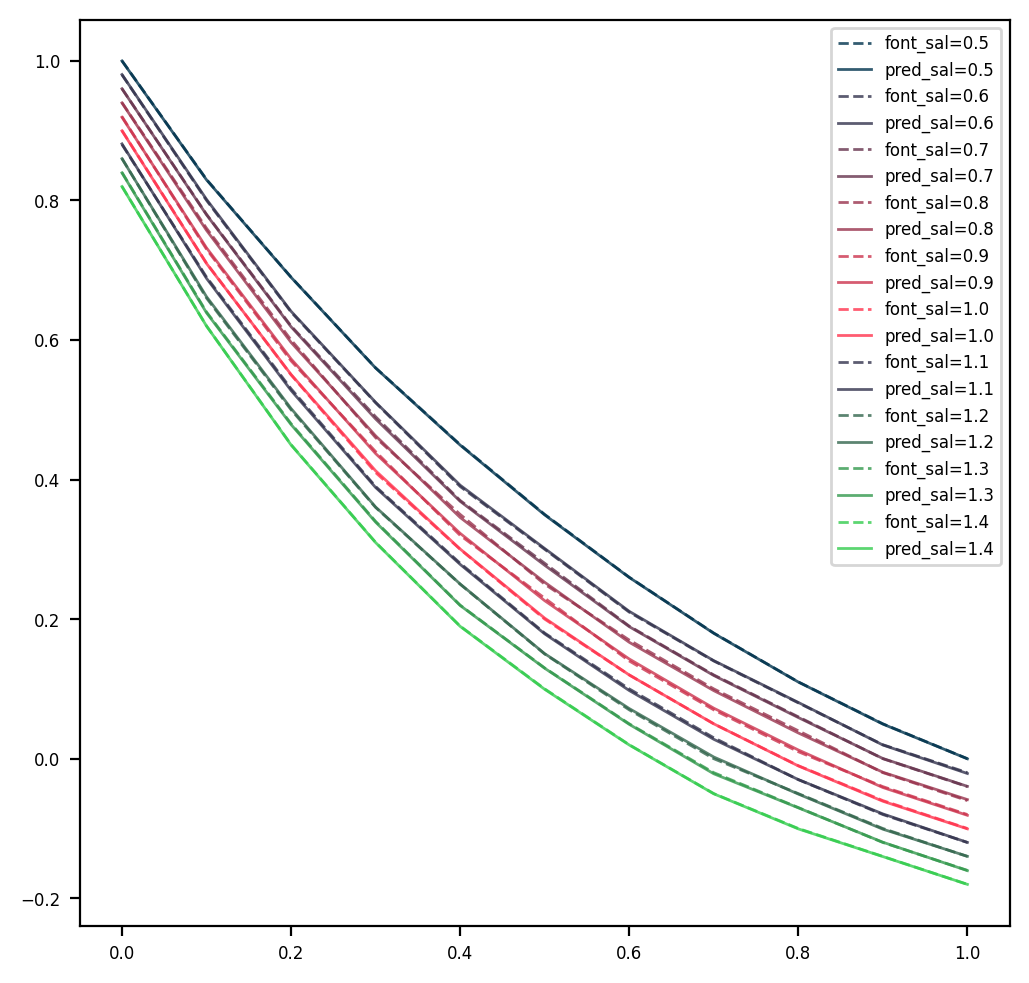

In [26]:
import matplotlib
matplotlib.rcParams.update({'font.size': 6})
# plt.plot(X_pred_del[0], Y_pred[0])
fig = plt.figure(figsize=(6,6), dpi=200)
for ii in range(len(a)):
    if ii<=5:
        ccc = (0.2*ii, 0.2, 0.3, 0.8)
    else:
        ccc = (0.2, 0.2*(ii-5), 0.3, 0.8)
    xxx_font = X[ii,0:len(x)]
    yyy_font = Y[ii,:]
    plt.plot(xxx_font, yyy_font, label='font_sal='+str(s[ii]), ls='--', color=ccc, lw=1)
    xxx_pred = X_pred_del[ii,:]
    yyy_pred = Y_pred[ii,:]
    plt.plot(xxx_pred, yyy_pred, label='pred_sal='+str(s[ii]), lw=1, color=ccc)
plt.legend()
plt.show()